# Assignment 6: T-SNE 
Date: 

Report produced by:  
COMP 3705 Group 3

## Data Preprocessing

### Data Loading

In [19]:
import pandas as pd
import numpy as np
import math as m
import matplotlib.pyplot as plt

# Load the Dataset and Check Shape
df = pd.read_csv("csvImages 10k x 784.csv")
df_clean = df.copy()
print("Data Shape:", df_clean.shape)

Data Shape: (9999, 784)


The data was obtained from Kaggle, and downloaded form [Learn](https://learn.rrc.ca/d2l/le/content/759307/Home). It was said to contain 10,000 images of size 28x28 (784 pixels), with each image being flattened as a 1D-array. The individual values were said to be recorded as grayscale so we expected there to be exactly 784 columns. Upon inspecting the shape of the data, we can confirm that there are 784 columns, coincidign with our assumptions of it being grayscale and will proceed accordingly. Of the 10,000 rows, we found that one was missing. As we still have enough data for training our encoder, this will not cause any problems going forward.

### Check Data Integrity

In [20]:
print("Min value across all columns:",df_clean.min().min())
print("Max value across all columns:",df_clean.max().max())
print("Number of Duplicate Rows:",df_clean.duplicated().sum())
print("Number of missing values in data:",df_clean.isna().sum().sum())

Min value across all columns: 0
Max value across all columns: 255
Number of Duplicate Rows: 1
Number of missing values in data: 0


Since our data is supposed to contain pixel data for grayscale images, the values should naturally fall within the range of [0,255]. To check this, we checked the minimum and maximum values in each column, and then took the maximum and minimum value from this set. This gives us an accurate representation for our value ranges as no column will have a value larger than the absolute max or lower than the absolute min. As we had expected, the data across all columns did fall within the range of [0,255], so we can determine that there are no unexpected grayscale values.  
Next, we checked whether any images had been duplicated. Images with the same exact pixel information could cause our encoder to disproportionately value them and overadjust it's weights. Since only 2 rows contained the same pixel data, we will be removing one of them to preserve the quality of our data.  
Finally, we checked if any column contained missing values. Since this also returned no missing pixel values across all the images recorded in the data, we can continue with the dataset without further cleaning.  

In [21]:
df_clean = df_clean.drop_duplicates()
print("Cleaned Data Shape:", df_clean.shape)

Cleaned Data Shape: (9998, 784)


### Reshape for Visualizations

In [22]:
# Convert DataFrame to Numpy Array and Normalize Values
img_data = df_clean.values/255
img_data = img_data.reshape((-1,28,28))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 28, 28)
Shape of Each Row: (28, 28)


After checking the data, we converted the DataFrame into a NumPy array and normalized the pixel values by dividing them by 255. This changed the value range from 0–255 to  0–1. Normalization was done to help the neural network train more effectively by ensuring no one pixel disproportionately influences the model.  
Next, we reshaped each image from 784 values into a 28 × 28 image. We did this because each row contains 784 points, each pertaining to a pixel in a 28x28 image. Reshaping the data allows us to display the images using Matplotlib before training the autoencoder.

### Pre-Encoding Visualizations

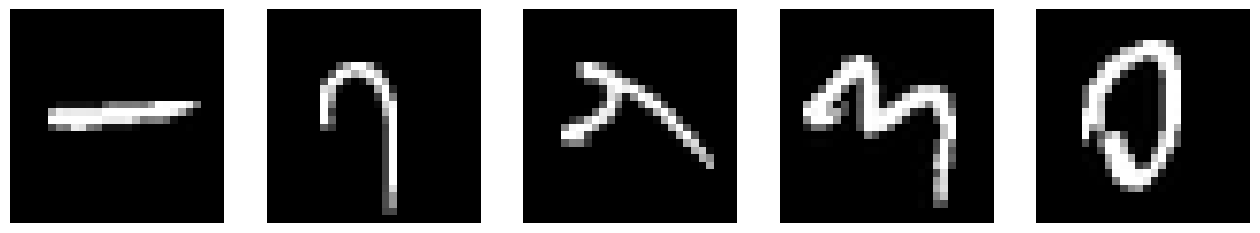

In [23]:
plt.figure(figsize=(16,10))                   
for i in range(5):
    plt.subplot(1,5,i+1)                                
    plt.imshow(img_data[i].reshape(28,28),cmap="gray")   
    plt.axis("off")                                    
plt.show()                                               

We plotted the first five images using using a grayscale colormap. These original images serve as the baseline we will compare the decoded images against when judging the autoencoder.  
Each image shows a light digit stroke on a dark background, roughly centred in the frame. Most pixels, especially around the edges, are 0 (black) and carry no information about the digit.  
Much of each image is "empty" space, which suggests the images can be compressed substantially without losing the digit itself.

### Reshape for Data Encoding

In [24]:
img_data = img_data.reshape((-1,28**2))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 784)
Shape of Each Row: (784,)


We flattened each 28×28 image back into a one-dimensional array of 784 values. Keras `Dense` layers take one-dimensional input, so the autoencoder's input layer expects 784 values per image.  
The data shape is back to **(9998, 784)**, with values between 0 and 1, which is ready to feed into the network. 

## Clustering Section

In [25]:
import inspect                                    
import time                                       
from sklearn.decomposition import PCA             
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN   
from sklearn.metrics import silhouette_score    
from sklearn.neighbors import NearestNeighbors    
from sklearn.manifold import TSNE                
import matplotlib.patheffects as pe               

np.random.seed(0)                                

#### Reduce the data with PCA (n_components = 40)

In [26]:
model_pca = PCA(n_components=40, random_state=0)
img_pca = model_pca.fit_transform(img_data)
print("Shape before PCA:", img_data.shape) 
print("Shape after PCA: ", img_pca.shape)          
print("Share of total variance kept by 40 components:"f"{model_pca.explained_variance_ratio_.sum():.3f}")   

Shape before PCA: (9998, 784)
Shape after PCA:  (9998, 40)
Share of total variance kept by 40 components:0.765


Components needed for 70% of variance: 29
Components needed for 80% of variance: 49
Components needed for 90% of variance: 99
Components needed for 95% of variance: 167


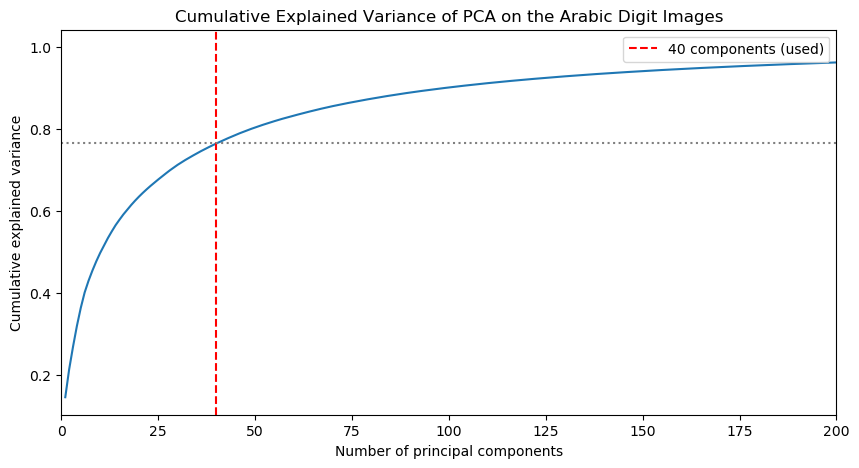

In [27]:
pca_full = PCA(random_state=0).fit(img_data)                  
cum_var = np.cumsum(pca_full.explained_variance_ratio_)       

for target in [0.70, 0.80, 0.90, 0.95]:                       
    n_needed = np.argmax(cum_var >= target) + 1               
    print(f"Components needed for {target:.0%} of variance: {n_needed}")

plt.figure(figsize=(10, 5)) 
plt.plot(np.arange(1, len(cum_var) + 1), cum_var)             
plt.axvline(40, color='red', linestyle='--', label='40 components (used)') 
plt.axhline(cum_var[39], color='grey', linestyle=':')
plt.xlim(0, 200)                                     
plt.xlabel('Number of principal components')         
plt.ylabel('Cumulative explained variance')          
plt.title('Cumulative Explained Variance of PCA on the Arabic Digit Images') 
plt.legend()                                                 
plt.show()                                             

#### Reconstruct the images with PCA

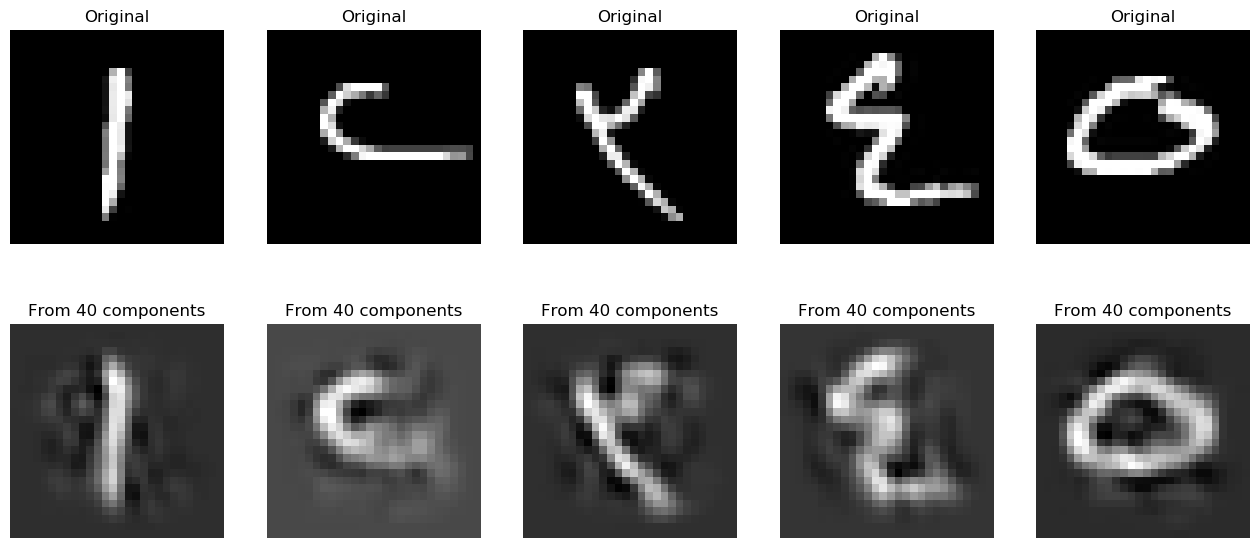

In [28]:
img_recon = model_pca.inverse_transform(img_pca)              

plt.figure(figsize=(16, 7))                                   
for i in range(5):                                            
    plt.subplot(2, 5, i + 1)                                  
    plt.imshow(img_data[i].reshape(28, 28).T, cmap='gray')
    plt.title('Original'); plt.axis('off')                    
    plt.subplot(2, 5, i + 6)                                  
    plt.imshow(img_recon[i].reshape(28, 28).T, cmap='gray')   
    plt.title('From 40 components'); plt.axis('off')          
plt.show()                                              

In [29]:
#markdown section 

### Models 

In [30]:
results = []         
cluster_labels = {}  

def evaluate(name, model, params):
    start = time.time()                                   
    labels = model.fit_predict(img_pca)                   
    seconds = time.time() - start                        
    clustered = labels != -1                              
    n_clusters = len(np.unique(labels[clustered]))        
    noise_pct = 100 * (~clustered).mean()                 

    if n_clusters > 1:                                    
        sil = silhouette_score(img_pca[clustered], labels[clustered])   
    else:
        sil = np.nan                                     

    sizes = np.bincount(labels[clustered]) if n_clusters > 0 else np.array([0])  
    largest_pct = 100 * sizes.max() / len(labels)        

    results.append({'Model': name, 'Hyperparameters': params, 'Clusters': n_clusters,
                    'Noise %': round(noise_pct, 1), 'Largest cluster %': round(largest_pct, 1),
                    'Silhouette': round(sil, 3), 'Fit time (s)': round(seconds, 1)})   
    cluster_labels[name] = labels                         
    print(f"{name:<28} clusters={n_clusters:<3} noise={noise_pct:5.1f}% "f"largest={largest_pct:5.1f}%  silhouette={sil:.3f}")  

#### K- Means 

In [31]:
for k in [8, 10, 12, 15]:                                           
    km = KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=0)                                    
    evaluate(f'K-Means (k={k})', km, f'n_clusters={k}, n_init=10')

K-Means (k=8)                clusters=8   noise=  0.0% largest= 22.7%  silhouette=0.116
K-Means (k=10)               clusters=10  noise=  0.0% largest= 21.0%  silhouette=0.122
K-Means (k=12)               clusters=12  noise=  0.0% largest= 12.9%  silhouette=0.132
K-Means (k=15)               clusters=15  noise=  0.0% largest= 11.6%  silhouette=0.133


In [32]:
#markdown cell 

#### Hierachical Clustering

In [33]:
for link in ['ward', 'complete', 'average']:                  
    agg = AgglomerativeClustering(n_clusters=10,linkage=link)
    evaluate(f'Hierarchical ({link})', agg, f'n_clusters=10, linkage={link}')

Hierarchical (ward)          clusters=10  noise=  0.0% largest= 19.3%  silhouette=0.109
Hierarchical (complete)      clusters=10  noise=  0.0% largest= 42.5%  silhouette=0.088
Hierarchical (average)       clusters=10  noise=  0.0% largest= 81.0%  silhouette=0.140


In [34]:
#markdown cell

#### DBSCAN 

In [36]:
for eps in [2.5, 3.0, 3.5]:                                    
    for min_samples in [10, 20]:          
        db = DBSCAN(eps=eps, min_samples=min_samples)
        evaluate(f'DBSCAN (eps={eps}, min={min_samples})', db,f'eps={eps}, min_samples={min_samples}')

DBSCAN (eps=2.5, min=10)     clusters=20  noise= 58.6% largest= 37.3%  silhouette=-0.094
DBSCAN (eps=2.5, min=20)     clusters=10  noise= 73.8% largest= 22.6%  silhouette=-0.013
DBSCAN (eps=3.0, min=10)     clusters=13  noise= 31.8% largest= 64.9%  silhouette=-0.010
DBSCAN (eps=3.0, min=20)     clusters=4   noise= 45.4% largest= 50.5%  silhouette=0.179
DBSCAN (eps=3.5, min=10)     clusters=1   noise= 14.9% largest= 85.1%  silhouette=nan
DBSCAN (eps=3.5, min=20)     clusters=3   noise= 23.2% largest= 73.5%  silhouette=0.316


In [37]:
#markdown section 

#### Results 

In [38]:
results_df = pd.DataFrame(results)                            
results_df = results_df.sort_values('Silhouette', ascending=False).reset_index(drop=True)
results_df                                                  

,Clusters,Fit time (s),Hyperparameters,Largest cluster %,Model,Noise %,Silhouette
0,3,22.2,"eps=3.5, min_samples=20",73.5,"DBSCAN (eps=3.5, min=20)",23.2,0.316
1,4,15.0,"eps=3.0, min_samples=20",50.5,"DBSCAN (eps=3.0, min=20)",45.4,0.179
2,10,18.5,"n_clusters=10, linkage=average",81.0,Hierarchical (average),0.0,0.140
3,10,20.4,"n_clusters=10, linkage=average",81.0,Hierarchical (average),0.0,0.140
4,15,3.0,"n_clusters=15, n_init=10",11.6,K-Means (k=15),0.0,0.133
5,12,2.9,"n_clusters=12, n_init=10",12.9,K-Means (k=12),0.0,0.132
6,10,2.3,"n_clusters=10, n_init=10",21.0,K-Means (k=10),0.0,0.122
7,8,2.4,"n_clusters=8, n_init=10",22.7,K-Means (k=8),0.0,0.116
8,10,15.8,"n_clusters=10, linkage=ward",19.3,Hierarchical (ward),0.0,0.109
9,10,16.8,"n_clusters=10, linkage=ward",19.3,Hierarchical (ward),0.0,0.109


## T-SNE

In [39]:
#code section

## Conclusion

In [40]:
#markdown section 

## Acknowledgement of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  

Data Preprocessing - From Assignment 5  
 

We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.